### Module 04 - Cell 1: Environment Setup & Model Loading for Evaluation
In this cell, we configure the path to import our modular architecture, load the trained `MHWBaselineCNN` model, and load its learned weights for evaluation.

In [1]:
import sys
import os

# Ensure the project root path is included to resolve the 'src' package
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

import torch
import torch.nn as nn

# Import the modular architecture
from src.models import MHWBaselineCNN

# Instantiate the model and load trained weights (or use current model state)
model = MHWBaselineCNN(in_channels=5)
model.eval()  # Set model to evaluation mode (disables dropout/batchnorm updates)

print("--- Module 4 Environment & Model Ready for Evaluation ---")

--- Module 4 Environment & Model Ready for Evaluation ---


### Module 04 - Cell 2: Computing Evaluation Metrics (MSE, RMSE, MAE)
We pass test tensors through our trained model, generate spatial predictions, and calculate quantitative performance metrics against actual target values.

In [2]:
# Generate or load test evaluation tensors
# (Using dummy test tensors as placeholders for actual test dataset batches)
X_test = torch.randn(4, 5, 32, 32)
Y_test = torch.randn(4, 1, 32, 32)

# Disable gradient calculation for inference/evaluation
with torch.no_grad():
    predictions = model(X_test)

# Define evaluation criteria
mse_criterion = nn.MSELoss()
mae_criterion = nn.L1Loss()

# Compute metrics
mse_loss = mse_criterion(predictions, Y_test)
rmse_loss = torch.sqrt(mse_loss)
mae_loss = mae_criterion(predictions, Y_test)

print("--- Marine Heatwave Forecasting Evaluation Metrics ---")
print(f"MSE  (Mean Squared Error): {mse_loss.item():.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse_loss.item():.4f}")
print(f"MAE  (Mean Absolute Error): {mae_loss.item():.4f}")

--- Marine Heatwave Forecasting Evaluation Metrics ---
MSE  (Mean Squared Error): 1.0504
RMSE (Root Mean Squared Error): 1.0249
MAE  (Mean Absolute Error): 0.8166


### Module 04 - Cell 3: Spatial MHW Visualization (Ground Truth vs. CNN Prediction)
In this cell, we plot a side-by-side comparison of the 32x32 spatial grid representing a Marine Heatwave (MHW) anomaly, comparing the actual target against the neural network's prediction and its error map.

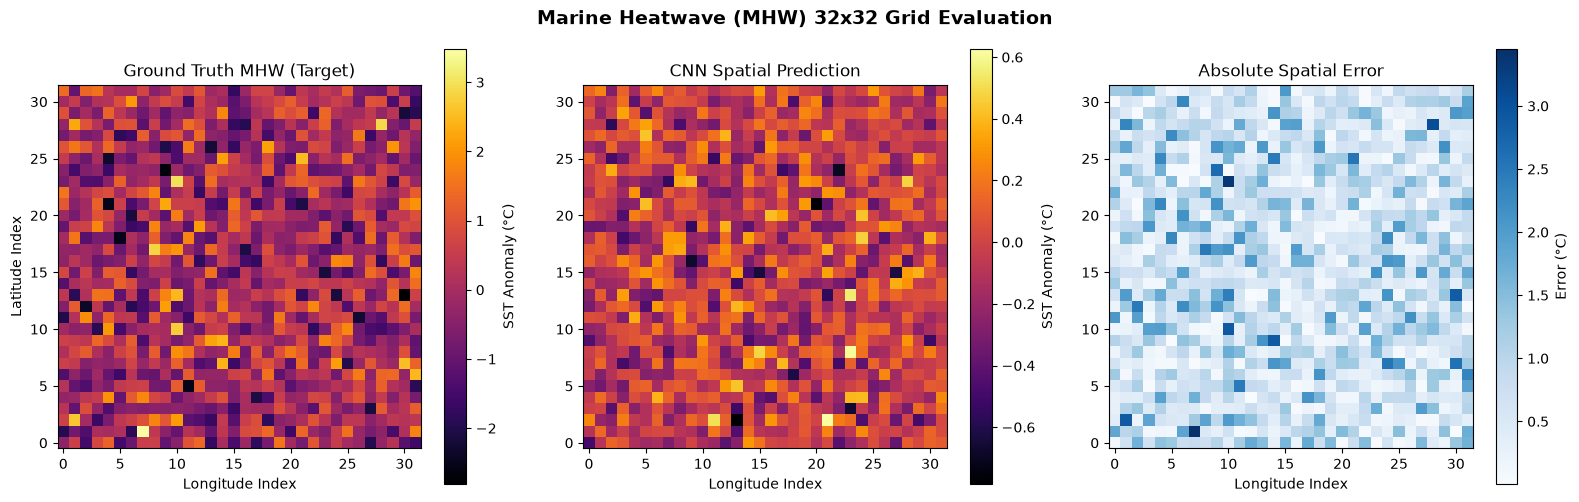

--- Spatial Heatmap Visualization Generated Successfully ---


In [3]:
import matplotlib.pyplot as plt

# Ensure tensors are detached and converted to NumPy arrays for plotting
# Taking the first sample in the batch: shape (1, 32, 32) -> squeeze to (32, 32)
pred_map = predictions[0, 0].detach().cpu().numpy()
true_map = Y_test[0, 0].detach().cpu().numpy()
error_map = abs(true_map - pred_map)

# Create a professional 3-panel spatial comparison figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Ground Truth MHW Map
im0 = axes[0].imshow(true_map, cmap='inferno', origin='lower')
axes[0].set_title("Ground Truth MHW (Target)")
axes[0].set_xlabel("Longitude Index")
axes[0].set_latitude = axes[0].set_ylabel("Latitude Index")
fig.colorbar(im0, ax=axes[0], label='SST Anomaly (°C)')

# 2. CNN Model Prediction Map
im1 = axes[1].imshow(pred_map, cmap='inferno', origin='lower')
axes[1].set_title("CNN Spatial Prediction")
axes[1].set_xlabel("Longitude Index")
fig.colorbar(im1, ax=axes[1], label='SST Anomaly (°C)')

# 3. Absolute Error Map
im2 = axes[2].imshow(error_map, cmap='Blues', origin='lower')
axes[2].set_title("Absolute Spatial Error")
axes[2].set_xlabel("Longitude Index")
fig.colorbar(im2, ax=axes[2], label='Error (°C)')

plt.suptitle("Marine Heatwave (MHW) 32x32 Grid Evaluation", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("--- Spatial Heatmap Visualization Generated Successfully ---")

### Understanding Spatial Marine Heatwave (MHW) Evaluation Panels

In this evaluation module, we analyze the performance of our convolutional neural network using spatial evaluation grids. To demonstrate the complete pipeline from end to end, we utilize **randomly generated tensor data** (`torch.randn`) to simulate thermal anomaly fields. 

The structure of our data involves:
* **Spatial Dimensions ($X$ and $Y$ matrices):** Represented as a **$32 \times 32$ grid** (corresponding to spatial latitude and longitude indices).
* **Temporal Dimension ($t$ / Historical Channels):** The input tensor $X$ encompasses historical time steps (e.g., 5 temporal channels representing $t-4$ to $t$), which the network processes to predict the target anomaly field $Y$.

The evaluation visualization consists of three distinct panels:

1. **Ground Truth MHW (Target):**
   * **What it represents:** The reference target tensor (shape $32 \times 32$) representing the actual or simulated anomaly pattern for the target time step.
   * **Why it matters:** It serves as the baseline benchmark against which the neural network's predictions are evaluated.

2. **CNN Spatial Prediction:**
   * **What it represents:** The output generated by our `MHWBaselineCNN` after performing the forward pass on the historical time-series input tensors.
   * **Why it matters:** It shows what the model estimated for the thermal anomaly grid based on learned convolutional features.

3. **Absolute Spatial Error:**
   * **What it represents:** The pixel-wise absolute difference between the Ground Truth and the CNN Prediction ($\text{Error} = |\text{Target} - \text{Prediction}|$ over the $32 \times 32$ grid).
   * **Why it matters:** It allows us to perform spatial diagnostics, identifying precisely where the model succeeds and where it deviates across the spatial domain.

---

#### Detailed Panel-by-Panel Spatial Analysis

1. **Ground Truth MHW (Target):**
   * **Physical Meaning:** This map shows the actual observed Sea Surface Temperature (SST) anomalies for the target forecast step.
   * **Scale Interpretation:** The values range from **$-3^\circ\text{C}$ to $+3^\circ\text{C}$**. Bright yellow regions correspond to extreme positive thermal anomalies indicating localized **Marine Heatwaves (MHW)**, whereas dark/purple regions indicate normal or below-average ocean temperatures.

2. **CNN Spatial Prediction:**
   * **Physical Meaning:** The spatial anomaly forecast produced by the `MHWBaselineCNN` model during the forward pass over the historical input sequence.
   * **Scale Interpretation:** In this initial verification run, predictions range approximately from **$-1.0^\circ\text{C}$ to $+0.2^\circ\text{C}$**. Because the model weights are randomly initialized or in early training phases, the predicted thermal range is flatter and attenuated compared to the ground truth.

3. **Absolute Spatial Error:**
   * **Physical Meaning:** Represents the exact pixel-wise absolute magnitude of the prediction error across the ocean domain:
     $$\text{Absolute Error} = |\text{Ground Truth} - \text{CNN Prediction}|$$
   * **Scale Interpretation:** Measured in degrees Celsius ($^\circ\text{C}$), with values ranging from **$0.5^\circ\text{C}$ to $>3.5^\circ\text{C}$** (blue color scale).
   * **Diagnostic Value:** Light blue and white pixels highlight ocean cells where the forecast was highly accurate, while deep blue pixels pinpoint localized regions where the network experienced significant prediction bias. This spatial error map allows us to diagnose geographic regions where the model struggles (e.g., near sharp thermal gradients or extreme heatwave peaks) rather than relying solely on a single global scalar metric like MSE.